In [5]:
import os
import math
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, Subset
import torchvision
from torchvision import datasets, transforms
import torchvision.transforms.functional as TF

from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# Set visual style and device
plt.style.use('seaborn-v0_8-whitegrid')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using computation device: {device}")

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)

# 1. Standard 10 Classes
CLASS_NAMES = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# 2. Structural Super-Categories (Silhouette & Body Placement)
STRUCTURAL_GROUPS = {
    'Upper Body': [0, 2, 4, 6],        # T-shirt/top, Pullover, Coat, Shirt
    'Lower & Full Body': [1, 3],       # Trouser, Dress
    'Footwear': [5, 7, 9],             # Sandal, Sneaker, Ankle boot
    'Accessories': [8]                 # Bag
}

# 3. Seasonal / Functional Super-Categories
SEASONAL_GROUPS = {
    'Warm Weather / Light': [0, 3, 5], # T-shirt/top, Dress, Sandal
    'Cold Weather / Heavy': [2, 4, 9], # Pullover, Coat, Ankle boot
    'All-Season / Staple': [1, 6, 7, 8]# Trouser, Shirt, Sneaker, Bag
}

# Helper maps from class_idx -> group_name
IDX_TO_STRUCTURAL = {idx: grp for grp, indices in STRUCTURAL_GROUPS.items() for idx in indices}
IDX_TO_SEASONAL = {idx: grp for grp, indices in SEASONAL_GROUPS.items() for idx in indices}

Using computation device: cuda


In [6]:
class KaggleFashionMNIST(Dataset):
    """Custom Dataset to load directly from Kaggle's fashion-mnist CSV files."""
    def __init__(self, csv_path, transform=None):
        df = pd.read_csv(csv_path)
        self.labels = df.iloc[:, 0].values.astype(np.int64)
        self.images = df.iloc[:, 1:].values.reshape(-1, 28, 28).astype(np.uint8)
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = self.labels[idx]
        img = TF.to_pil_image(img)
        if self.transform:
            img = self.transform(img)
        return img, label

# Normalization constants for Fashion-MNIST
MEAN, STD = (0.2860,), (0.3530,)

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomCrop(28, padding=2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

kaggle_train_path = '/kaggle/input/fashionmnist/fashion-mnist_train.csv'
kaggle_test_path = '/kaggle/input/fashionmnist/fashion-mnist_test.csv'

if os.path.exists(kaggle_train_path) and os.path.exists(kaggle_test_path):
    print("Loading Fashion-MNIST from Kaggle CSV directory...")
    train_dataset = KaggleFashionMNIST(kaggle_train_path, transform=train_transform)
    test_dataset = KaggleFashionMNIST(kaggle_test_path, transform=eval_transform)
    raw_test_dataset = KaggleFashionMNIST(kaggle_test_path, transform=transforms.ToTensor())
else:
    print("Downloading Fashion-MNIST via torchvision...")
    train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=train_transform)
    test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=eval_transform)
    raw_test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

BATCH_SIZE = 128
use_cuda = torch.cuda.is_available()
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=use_cuda)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=use_cuda)

print(f"Train samples: {len(train_dataset):,} | Test samples: {len(test_dataset):,}")

Train samples: 60,000 | Test samples: 10,000


In [7]:
def conv3x3(in_planes, out_planes, stride=1):
    """3x3 convolution with padding"""
    return nn.Conv2d(in_planes, out_planes, kernel_size=3, stride=stride, padding=1, bias=False)

class BasicBlock(nn.Module):
    expansion = 1

    def __init__(self, inplanes, planes, stride=1, downsample=None):
        super(BasicBlock, self).__init__()
        self.conv1 = conv3x3(inplanes, planes, stride)
        self.bn1 = nn.BatchNorm2d(planes)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = conv3x3(planes, planes)
        self.bn2 = nn.BatchNorm2d(planes)
        self.downsample = downsample
        self.stride = stride

    def forward(self, x):
        residual = x
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            residual = self.downsample(x)

        out += residual
        out = self.relu(out)
        return out

class ResNet(nn.Module):
    """ResNet18 implementation adapted for Fashion-MNIST (kefth/fashion-mnist)."""
    def __init__(self, block, layers, num_classes=10):
        self.inplanes = 64
        super(ResNet, self).__init__()
        self.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = self._make_layer(block, 64, layers[0])
        self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
        self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
        self.avgpool = nn.AvgPool2d(7)
        self.fc = nn.Linear(256 * block.expansion, num_classes)

        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                n = m.kernel_size[0] * m.kernel_size[1] * m.out_channels
                m.weight.data.normal_(0, math.sqrt(2. / n))
            elif isinstance(m, nn.BatchNorm2d):
                m.weight.data.fill_(1)
                m.bias.data.zero_()

    def _make_layer(self, block, planes, blocks, stride=1):
        downsample = None
        if stride != 1 or self.inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(self.inplanes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes * block.expansion),
            )

        layers = []
        layers.append(block(self.inplanes, planes, stride, downsample))
        self.inplanes = planes * block.expansion
        for i in range(1, blocks):
            layers.append(block(self.inplanes, planes))

        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)

        x = self.avgpool(x)
        x = x.view(x.size(0), -1)
        return self.fc(x)

def resnet18(**kwargs):
    return ResNet(BasicBlock, [2, 2, 2, 2], **kwargs)

model = resnet18(num_classes=10).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"kefth ResNet18 initialized — Total trainable parameters: {total_params:,}")

kefth ResNet18 initialized — Total trainable parameters: 2,776,522


In [8]:
EPOCHS = 15
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch}/{EPOCHS} [Train]", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(imgs)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * imgs.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)

    scheduler.step()
    train_loss, train_acc = running_loss / total, correct / total

    # Validation pass
    model.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            logits = model(imgs)
            loss = criterion(logits, labels)
            val_loss += loss.item() * imgs.size(0)
            val_correct += (logits.argmax(dim=1) == labels).sum().item()
            val_total += labels.size(0)

    val_loss, val_acc = val_loss / val_total, val_correct / val_total
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    print(f"Epoch {epoch:02d} | Train Loss: {train_loss:.4f} Acc: {train_acc:.4f} | Test Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

# Strict Black-Box Evaluation: Collect outputs P(Y|X) and ground truth targets only
def collect_blackbox_predictions(model, loader):
    model.eval()
    all_probs, all_targets = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            logits = model(imgs)
            probs = F.softmax(logits, dim=1)
            all_probs.append(probs.cpu().numpy())
            all_targets.append(labels.numpy())

    return np.vstack(all_probs), np.concatenate(all_targets)

probs, targets = collect_blackbox_predictions(model, test_loader)
preds = probs.argmax(axis=1)

# Black-Box uncertainty diagnostics derived purely from the probability outputs
sorted_probs = np.sort(probs, axis=1)[:, ::-1]
top1_conf = sorted_probs[:, 0]
top2_conf = sorted_probs[:, 1]
pred_margin = top1_conf - top2_conf
shannon_entropy = -np.sum(probs * np.log(np.clip(probs, 1e-12, 1.0)), axis=1)

print(f"Evaluation complete across {len(targets):,} test items.")
print(f"Overall Black-Box Accuracy: {(preds == targets).mean() * 100:.2f}%")

Epoch 1/15 [Train]:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 0.4983 Acc: 0.8156 | Test Loss: 0.3664 Acc: 0.8683


Epoch 2/15 [Train]:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 02 | Train Loss: 0.3075 Acc: 0.8889 | Test Loss: 0.2787 Acc: 0.9016


Epoch 3/15 [Train]:   0%|          | 0/469 [00:00<?, ?it/s]

...

Epoch 13 | Train Loss: 0.1128 Acc: 0.9594 | Test Loss: 0.1675 Acc: 0.9426


Epoch 14/15 [Train]:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 14 | Train Loss: 0.1057 Acc: 0.9621 | Test Loss: 0.1652 Acc: 0.9423


Epoch 15/15 [Train]:   0%|          | 0/469 [00:00<?, ?it/s]

Epoch 15 | Train Loss: 0.1015 Acc: 0.9647 | Test Loss: 0.1636 Acc: 0.9422
Evaluation complete across 10,000 test items.
Overall Black-Box Accuracy: 94.22%


In [9]:
class BlackBoxModel:
    """
    Strict Black-Box Wrapper for Phase I.
    Exposes ONLY input -> softmax probability vector P(Y|X).
    No access to weights, gradients, or hidden activations.
    """
    def __init__(self, trained_model, device):
        self._model = trained_model.eval()
        self.device = device

    @torch.no_grad()
    def predict_proba(self, x_tensor):
        """Input: Normalized tensor [B, 1, 28, 28] -> Output: numpy array [B, 10] of probabilities."""
        logits = self._model(x_tensor.to(self.device))
        return F.softmax(logits, dim=1).cpu().numpy()

blackbox = BlackBoxModel(model, device)

# Collect Black-Box Outputs across the entire Test Set
all_probs, all_targets = [], []
for imgs, labels in test_loader:
    all_probs.append(blackbox.predict_proba(imgs))
    all_targets.append(labels.numpy())

probs = np.vstack(all_probs)          # Shape: [10000, 10]
targets = np.concatenate(all_targets) # Shape: [10000]
preds = probs.argmax(axis=1)          # Top-1 Predicted Class

# Compute Black-Box Uncertainty Metrics from Output Distribution Alone
sorted_probs = np.sort(probs, axis=1)[:, ::-1]
top1_conf = sorted_probs[:, 0]                        # P(y_hat_1 | x)
top2_conf = sorted_probs[:, 1]                        # P(y_hat_2 | x)
pred_margin = top1_conf - top2_conf                   # Margin between #1 and #2 choice
entropy = -np.sum(probs * np.log(np.clip(probs, 1e-12, 1.0)), axis=1) # Shannon Entropy

df_bb = pd.DataFrame({
    'True_Idx': targets,
    'Pred_Idx': preds,
    'True_Class': [CLASS_NAMES[i] for i in targets],
    'Pred_Class': [CLASS_NAMES[i] for i in preds],
    'True_Structural': [IDX_TO_STRUCTURAL[i] for i in targets],
    'Pred_Structural': [IDX_TO_STRUCTURAL[i] for i in preds],
    'True_Seasonal': [IDX_TO_SEASONAL[i] for i in targets],
    'Pred_Seasonal': [IDX_TO_SEASONAL[i] for i in preds],
    'Correct': preds == targets,
    'Top1_Conf': top1_conf,
    'Top2_Conf': top2_conf,
    'Margin': pred_margin,
    'Entropy': entropy
})

print(f"Black-Box Overall Test Accuracy: {df_bb['Correct'].mean()*100:.2f}%")

Black-Box Overall Test Accuracy: 94.22%


In [10]:
# 1. Extract Top-10 Most Frequent Confusion Pairs (True -> Predicted)
errors_df = df_bb[~df_bb['Correct']].copy()
confusion_pairs = (
    errors_df.groupby(['True_Class', 'Pred_Class', 'True_Structural', 'Pred_Structural'])
    .agg(
        Error_Count=('Correct', 'count'),
        Mean_Conf_On_Error=('Top1_Conf', 'mean'),
        Mean_Margin_On_Error=('Margin', 'mean')
    )
    .reset_index()
    .sort_values(by='Error_Count', ascending=False)
)
confusion_pairs['Same_Structural_Group'] = confusion_pairs['True_Structural'] == confusion_pairs['Pred_Structural']

print("Top 10 Most Frequent Misclassification Pairs:")
display(confusion_pairs.head(10).style.background_gradient(cmap='Reds', subset=['Error_Count', 'Mean_Conf_On_Error']))

# 2. Hierarchical Group Performance Breakdown
def summarize_group_behavior(df, true_col, pred_col, group_label):
    records = []
    for grp in df[true_col].unique():
        sub = df[df[true_col] == grp]
        sub_err = sub[~sub['Correct']]
        intra_err = (sub_err[pred_col] == grp).mean() if len(sub_err) > 0 else 0.0
        records.append({
            f'{group_label} Category': grp,
            'Sample Count': len(sub),
            'Fine-Grained Acc (10-class)': sub['Correct'].mean(),
            'Group-Level Acc (Super-class)': (sub[pred_col] == grp).mean(),
            '% of Errors Staying Inside Group': intra_err * 100,
            'Mean Confidence': sub['Top1_Conf'].mean(),
            'Mean Margin (p1 - p2)': sub['Margin'].mean()
        })
    return pd.DataFrame(records).sort_values(by='Fine-Grained Acc (10-class)')

print("\nBehavioral Summary by STRUCTURAL Category:")
display(summarize_group_behavior(df_bb, 'True_Structural', 'Pred_Structural', 'Structural').style.format({
    'Fine-Grained Acc (10-class)': '{:.2%}',
    'Group-Level Acc (Super-class)': '{:.2%}',
    '% of Errors Staying Inside Group': '{:.1f}%',
    'Mean Confidence': '{:.3f}',
    'Mean Margin (p1 - p2)': '{:.3f}'
}))

print("\nBehavioral Summary by SEASONAL Category:")
display(summarize_group_behavior(df_bb, 'True_Seasonal', 'Pred_Seasonal', 'Seasonal').style.format({
    'Fine-Grained Acc (10-class)': '{:.2%}',
    'Group-Level Acc (Super-class)': '{:.2%}',
    '% of Errors Staying Inside Group': '{:.1f}%',
    'Mean Confidence': '{:.3f}',
    'Mean Margin (p1 - p2)': '{:.3f}'
}))

Top 10 Most Frequent Misclassification Pairs:


,True_Class,Pred_Class,True_Structural,Pred_Structural,Error_Count,Mean_Conf_On_Error,Mean_Margin_On_Error,Same_Structural_Group
27,Shirt,T-shirt/top,Upper Body,Upper Body,79,0.760293,0.540476,True
36,T-shirt/top,Shirt,Upper Body,Upper Body,69,0.721831,0.486852,True
24,Shirt,Coat,Upper Body,Upper Body,54,0.713465,0.469216,True
26,Shirt,Pullover,Upper Body,Upper Body,31,0.718715,0.502528,True
16,Pullover,Coat,Upper Body,Upper Body,30,0.748340,0.527986,True
18,Pullover,Shirt,Upper Body,Upper Body,29,0.708932,0.483376,True
1,Ankle boot,Sneaker,Footwear,Footwear,29,0.728147,0.459043,True
8,Coat,Shirt,Upper Body,Upper Body,27,0.742833,0.514279,True
7,Coat,Pullover,Upper Body,Upper Body,22,0.691257,0.448215,True
25,Shirt,Dress,Upper Body,Lower & Full Body,21,0.738191,0.575380,False



Behavioral Summary by STRUCTURAL Category:


,Structural Category,Sample Count,Fine-Grained Acc (10-class),Group-Level Acc (Super-class),% of Errors Staying Inside Group,Mean Confidence,Mean Margin (p1 - p2)
1,Upper Body,4000,88.95%,98.22%,83.9%,0.921,0.856
2,Lower & Full Body,2000,96.90%,97.25%,11.3%,0.972,0.952
0,Footwear,3000,97.70%,100.00%,100.0%,0.983,0.968
3,Accessories,1000,99.50%,99.50%,0.0%,0.994,0.989



Behavioral Summary by SEASONAL Category:


,Seasonal Category,Sample Count,Fine-Grained Acc (10-class),Group-Level Acc (Super-class),% of Errors Staying Inside Group,Mean Confidence,Mean Margin (p1 - p2)
0,Cold Weather / Heavy,3000,93.80%,95.53%,28.0%,0.956,0.918
2,Warm Weather / Light,3000,94.33%,95.10%,13.5%,0.954,0.917
1,All-Season / Staple,4000,94.45%,94.58%,2.3%,0.961,0.929


/tmp/ipykernel_780/2990780617.py:36: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=40, ha='right')
/tmp/ipykernel_780/2990780617.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(CLASS_NAMES, rotation=40, ha='right')


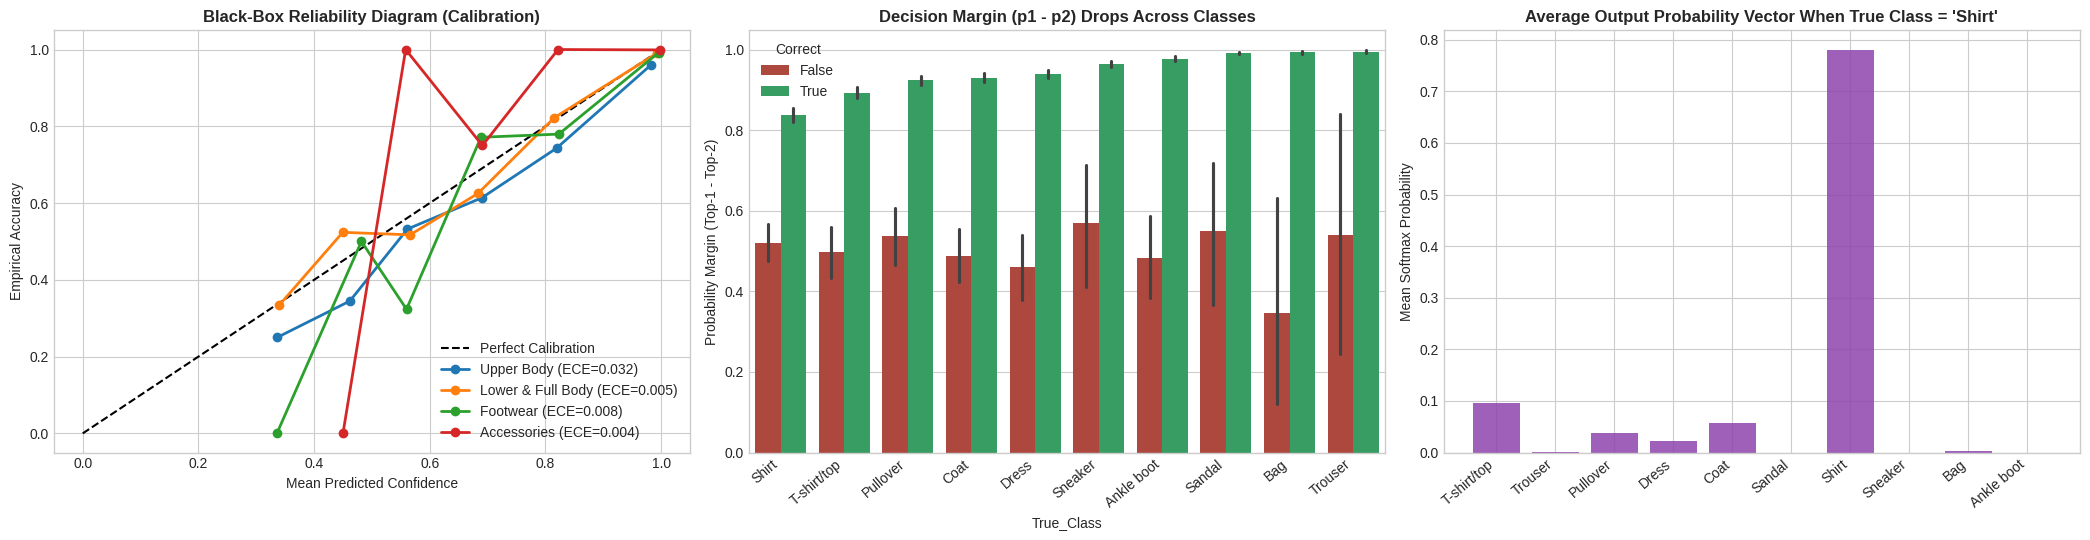

In [13]:
def compute_calibration_curve(confidences, accuracies, num_bins=10):
    bin_boundaries = np.linspace(0.0, 1.0, num_bins + 1)
    bin_accs, bin_confs, bin_counts = [], [], []
    ece = 0.0
    n = len(confidences)
    for i in range(num_bins):
        in_bin = (confidences > bin_boundaries[i]) & (confidences <= bin_boundaries[i + 1])
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            acc_in_bin = accuracies[in_bin].mean()
            conf_in_bin = confidences[in_bin].mean()
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_accs.append(acc_in_bin)
            bin_confs.append(conf_in_bin)
            bin_counts.append(in_bin.sum())
    return np.array(bin_confs), np.array(bin_accs), ece

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

# 1. Reliability Diagram (Calibration Curve) per Structural Group
axes[0].plot([0, 1], [0, 1], 'k--', label='Perfect Calibration')
for grp in STRUCTURAL_GROUPS.keys():
    sub = df_bb[df_bb['True_Structural'] == grp]
    b_conf, b_acc, ece = compute_calibration_curve(sub['Top1_Conf'].values, sub['Correct'].values, num_bins=8)
    axes[0].plot(b_conf, b_acc, marker='o', linewidth=2, label=f"{grp} (ECE={ece:.3f})")
axes[0].set_title("Black-Box Reliability Diagram (Calibration)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Mean Predicted Confidence")
axes[0].set_ylabel("Empirical Accuracy")
axes[0].legend(loc='lower right')

# 2. Probability Margin (Top-1 minus Top-2) by Class
order_by_margin = df_bb.groupby('True_Class')['Margin'].mean().sort_values().index
sns.barplot(data=df_bb, x='True_Class', y='Margin', hue='Correct', order=order_by_margin,
            palette={True: '#27ae60', False: '#c0392b'}, ax=axes[1])
axes[1].set_title("Decision Margin (p1 - p2) Drops Across Classes", fontsize=12, fontweight='bold')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=40, ha='right')
axes[1].set_ylabel("Probability Margin (Top-1 - Top-2)")

# 3. Softmax Probability Profile for 'Shirt' (Most Ambiguous Class)
shirt_mask = (df_bb['True_Class'] == 'Shirt')
shirt_mean_probs = probs[shirt_mask].mean(axis=0)
axes[2].bar(CLASS_NAMES, shirt_mean_probs, color='#8e44ad', alpha=0.85)
axes[2].set_title("Average Output Probability Vector When True Class = 'Shirt'", fontsize=12, fontweight='bold')
axes[2].set_xticklabels(CLASS_NAMES, rotation=40, ha='right')
axes[2].set_ylabel("Mean Softmax Probability")

plt.tight_layout()
plt.show()

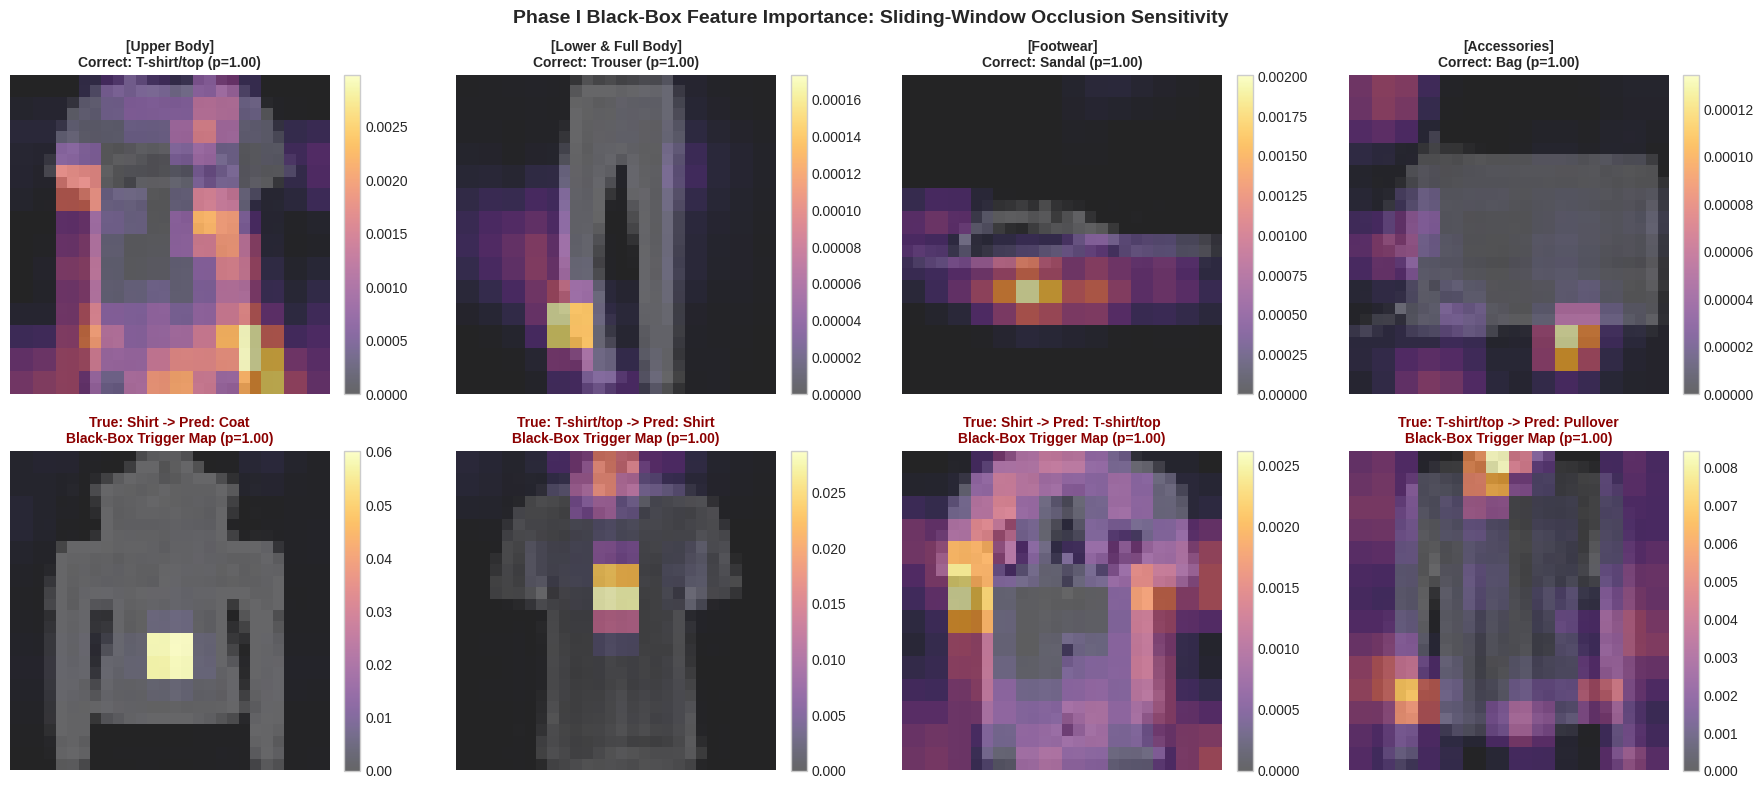

In [12]:
def blackbox_occlusion_map(blackbox_model, raw_img_tensor, target_class_idx, patch_size=4, stride=2):
    """
    Purely black-box spatial attribution!
    Occludes patches of the input image and measures drop in P(target_class | X).
    """
    # Baseline probability on unoccluded image
    norm_base = TF.normalize(raw_img_tensor, MEAN, STD).unsqueeze(0)
    base_prob = blackbox_model.predict_proba(norm_base)[0, target_class_idx]

    H, W = 28, 28
    heatmap = np.zeros((H, W), dtype=np.float32)
    counts = np.zeros((H, W), dtype=np.float32)

    occluded_batch = []
    coords = []
    for y in range(0, H - patch_size + 1, stride):
        for x in range(0, W - patch_size + 1, stride):
            occ = raw_img_tensor.clone()
            occ[:, y:y+patch_size, x:x+patch_size] = MEAN[0] # Replace with dataset mean gray
            occluded_batch.append(TF.normalize(occ, MEAN, STD))
            coords.append((y, x))

    batch_tensor = torch.stack(occluded_batch)
    occ_probs = blackbox_model.predict_proba(batch_tensor)[:, target_class_idx]

    for (y, x), occ_p in zip(coords, occ_probs):
        prob_drop = max(0.0, base_prob - occ_p) # Positive when occluding the region hurts confidence
        heatmap[y:y+patch_size, x:x+patch_size] += prob_drop
        counts[y:y+patch_size, x:x+patch_size] += 1.0

    heatmap /= np.maximum(counts, 1.0)
    return heatmap, base_prob

# Compare Black-Box Feature Importance on 4 Correct Representative Group Samples vs 4 Misclassifications
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

# Row 0: One correct prototype from each of the 4 Structural Groups
for col, (grp_name, grp_idxs) in enumerate(STRUCTURAL_GROUPS.items()):
    cand_idxs = np.where((targets == grp_idxs[0]) & (preds == targets) & (top1_conf > 0.95))[0]
    idx = cand_idxs[0]
    raw_img, lbl = raw_test_dataset[idx]
    occ_map, base_p = blackbox_occlusion_map(blackbox, raw_img, target_class_idx=lbl)

    axes[0, col].imshow(raw_img.squeeze(), cmap='gray', alpha=0.65)
    im = axes[0, col].imshow(occ_map, cmap='inferno', alpha=0.6)
    axes[0, col].set_title(f"[{grp_name}]\nCorrect: {CLASS_NAMES[lbl]} (p={base_p:.2f})", fontsize=10, fontweight='bold')
    axes[0, col].axis('off')
    plt.colorbar(im, ax=axes[0, col], fraction=0.046, pad=0.04)

# Row 1: Top-4 Confident Misclassifications — what visual region tricked the black box?
err_idxs = np.where(preds != targets)[0]
top_err = err_idxs[np.argsort(-top1_conf[err_idxs])[:4]]
for col, idx in enumerate(top_err):
    raw_img, true_lbl = raw_test_dataset[idx]
    pred_lbl = preds[idx]
    occ_map, base_p = blackbox_occlusion_map(blackbox, raw_img, target_class_idx=pred_lbl)

    axes[1, col].imshow(raw_img.squeeze(), cmap='gray', alpha=0.65)
    im = axes[1, col].imshow(occ_map, cmap='inferno', alpha=0.6)
    axes[1, col].set_title(f"True: {CLASS_NAMES[true_lbl]} -> Pred: {CLASS_NAMES[pred_lbl]}\nBlack-Box Trigger Map (p={base_p:.2f})",
                           fontsize=10, color='darkred', fontweight='bold')
    axes[1, col].axis('off')
    plt.colorbar(im, ax=axes[1, col], fraction=0.046, pad=0.04)

plt.suptitle("Phase I Black-Box Feature Importance: Sliding-Window Occlusion Sensitivity", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

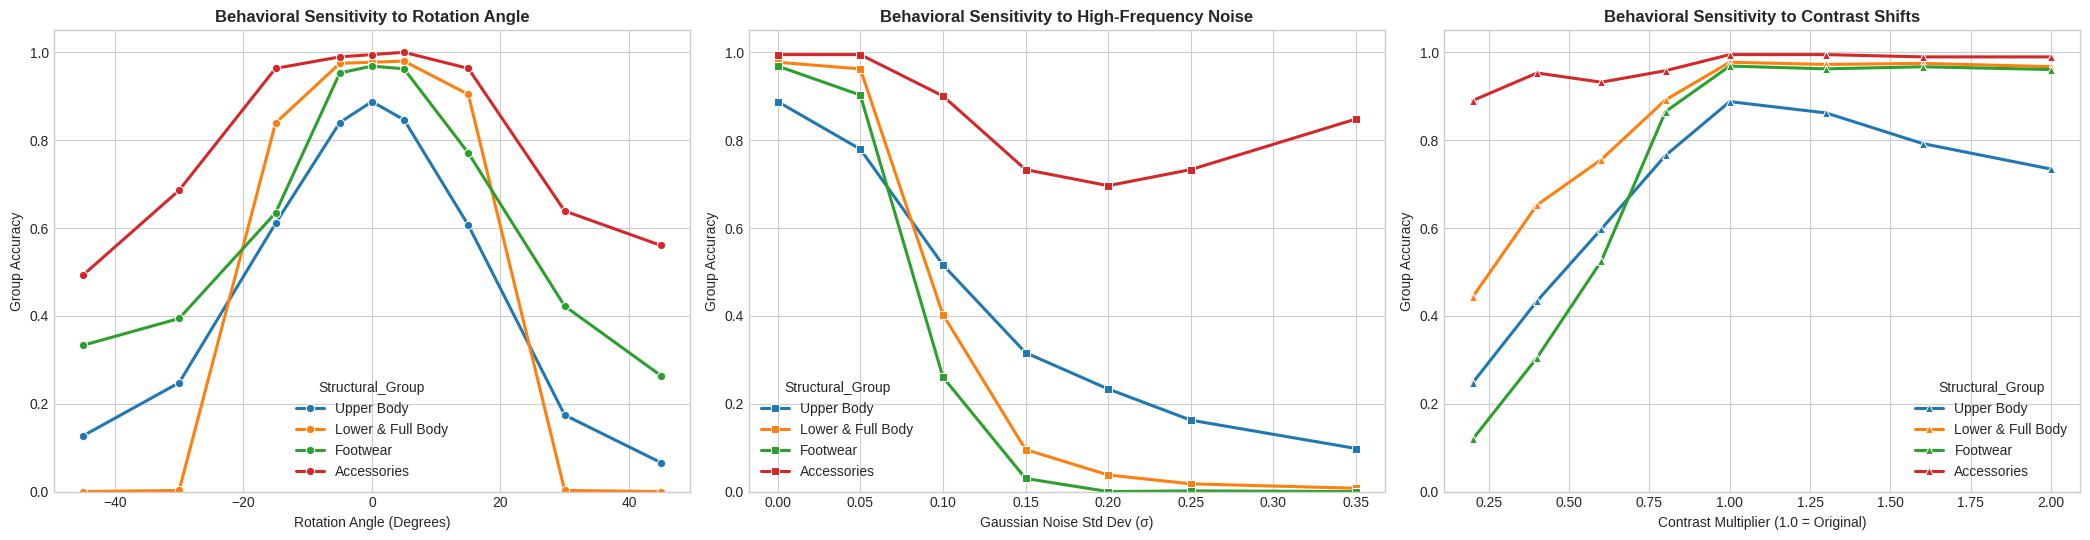

In [14]:
# Use a stratified 2,000-sample subset for fast parametric sweeps
sweep_indices = np.random.choice(len(raw_test_dataset), 2000, replace=False)
sweep_subset = Subset(raw_test_dataset, sweep_indices)
sweep_loader = DataLoader(sweep_subset, batch_size=256, shuffle=False)

def run_parametric_sweep(param_values, transform_builder):
    results = []
    for val in param_values:
        all_p, all_t, all_c = [], [], []
        for imgs, labels in sweep_loader:
            pert = torch.clamp(transform_builder(imgs, val), 0.0, 1.0)
            norm = TF.normalize(pert, MEAN, STD)
            prob = blackbox.predict_proba(norm)
            all_p.append(prob.argmax(axis=1))
            all_c.append(prob.max(axis=1))
            all_t.append(labels.numpy())
        p, t, c = np.concatenate(all_p), np.concatenate(all_t), np.concatenate(all_c)
        for grp, idxs in STRUCTURAL_GROUPS.items():
            mask = np.isin(t, idxs)
            results.append({
                'Param': val,
                'Structural_Group': grp,
                'Accuracy': (p[mask] == t[mask]).mean(),
                'Confidence': c[mask].mean()
            })
    return pd.DataFrame(results)

# Sweep 1: Rotation Angle (-45° to +45°)
rot_df = run_parametric_sweep(
    [-45, -30, -15, -5, 0, 5, 15, 30, 45],
    lambda x, angle: TF.rotate(x, angle=angle)
)

# Sweep 2: Additive High-Frequency Gaussian Noise (sigma 0.0 to 0.35)
noise_df = run_parametric_sweep(
    [0.0, 0.05, 0.10, 0.15, 0.20, 0.25, 0.35],
    lambda x, sigma: x + torch.randn_like(x) * sigma
)

# Sweep 3: Contrast Scaling (0.2x washed-out to 2.0x harsh contrast)
contrast_df = run_parametric_sweep(
    [0.2, 0.4, 0.6, 0.8, 1.0, 1.3, 1.6, 2.0],
    lambda x, factor: TF.adjust_contrast(x, contrast_factor=factor)
)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))

sns.lineplot(data=rot_df, x='Param', y='Accuracy', hue='Structural_Group', marker='o', linewidth=2.2, ax=axes[0])
axes[0].set_title("Behavioral Sensitivity to Rotation Angle", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Rotation Angle (Degrees)")
axes[0].set_ylabel("Group Accuracy")
axes[0].set_ylim(0, 1.05)

sns.lineplot(data=noise_df, x='Param', y='Accuracy', hue='Structural_Group', marker='s', linewidth=2.2, ax=axes[1])
axes[1].set_title("Behavioral Sensitivity to High-Frequency Noise", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Gaussian Noise Std Dev (σ)")
axes[1].set_ylabel("Group Accuracy")
axes[1].set_ylim(0, 1.05)

sns.lineplot(data=contrast_df, x='Param', y='Accuracy', hue='Structural_Group', marker='^', linewidth=2.2, ax=axes[2])
axes[2].set_title("Behavioral Sensitivity to Contrast Shifts", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Contrast Multiplier (1.0 = Original)")
axes[2].set_ylabel("Group Accuracy")
axes[2].set_ylim(0, 1.05)

plt.tight_layout()
plt.show()